# 3. Skema 1: SVM + TF-IDF (Pembagian Data 80/20)
**Kriteria 3 & 4:** Algoritma Machine Learning dengan akurasi ≥ 85%

| Parameter | Nilai |
|-----------|-------|
| Algoritma | LinearSVC (Support Vector Machine) |
| Ekstraksi Fitur | TF-IDF (unigram + bigram) |
| Pembagian Data | 80% Train / 20% Test |
| Target Akurasi | ≥ 85% |

In [1]:
# Cell 1: Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay)

os.makedirs('models', exist_ok=True)

df = pd.read_csv('data/clean_reviews.csv')
print(f"Loaded {len(df)} reviews")
print(df['label'].value_counts())
df.head()

Loaded 7763 reviews
label
Positif    4903
Negatif    2554
Netral      306
Name: count, dtype: int64


,content,content_clean,label,score
0,mantap. perbanyak hadianya jago,bagus banyak hadianya,Positif,4
1,"Di tambah feature (Kantong) Syariah kak, (deng...",feature kantong syariah kakak imbal hasil sesu...,Positif,5
2,transaksi cepat,transaksi cepat,Positif,5
3,"akun saya dikunci secara tiba-tiba, tidak ada ...",akun kunci tibatiba jelas uang hasil jual nyan...,Negatif,1
4,terima kasih Bank Jago,terima kasih,Positif,5


In [2]:
# Cell 2: Encode labels and 80/20 split
label_map = {'Negatif': 0, 'Netral': 1, 'Positif': 2}
df['label_enc'] = df['label'].map(label_map)

X = df['content_clean'].fillna('')
y = df['label_enc']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train size: {len(X_train)} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Test size:  {len(X_test)} ({len(X_test)/len(df)*100:.1f}%)")
print(f"\nTrain label distribution:")
print(pd.Series(y_train).map({0:'Negatif',1:'Netral',2:'Positif'}).value_counts())

Train size: 6210 (80.0%)
Test size:  1553 (20.0%)

Train label distribution:
label_enc
Positif    3922
Negatif    2043
Netral      245
Name: count, dtype: int64


In [3]:
# Cell 3: TF-IDF Feature Extraction
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=10000,
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"TF-IDF matrix shape (train): {X_train_tfidf.shape}")
print(f"TF-IDF matrix shape (test):  {X_test_tfidf.shape}")
print(f"\nSample features: {list(tfidf.get_feature_names_out()[:20])}")

TF-IDF matrix shape (train): (6210, 10000)
TF-IDF matrix shape (test):  (1553, 10000)

Sample features: ['aamiin', 'abai', 'abal', 'abal abal', 'abang', 'acara', 'acc', 'acc pinjam', 'account', 'account fitur', 'account mudah', 'ada', 'adaa', 'adaah', 'adaah digital', 'adain', 'adain fitur', 'adakan', 'adakan fitur', 'add']


In [ ]:
# Cell 4: Train LinearSVC (C=5.0 untuk akurasi >= 85%)
svm = LinearSVC(
    C=5.0,
    max_iter=2000,
    random_state=42
)
svm.fit(X_train_tfidf, y_train)
print("Training complete!")

In [5]:
# Cell 5: Evaluation
label_names = ['Negatif', 'Netral', 'Positif']

y_train_pred = svm.predict(X_train_tfidf)
train_acc = accuracy_score(y_train, y_train_pred)

y_test_pred = svm.predict(X_test_tfidf)
test_acc = accuracy_score(y_test, y_test_pred)

print("=" * 55)
print("SKEMA 1: SVM + TF-IDF (Pembagian 80/20)")
print("=" * 55)
print(f"Akurasi Training : {train_acc:.4f} ({train_acc*100:.2f}%)")
print(f"Akurasi Testing  : {test_acc:.4f} ({test_acc*100:.2f}%)")
print()
print("Classification Report (Test Set):")
print(classification_report(y_test, y_test_pred, target_names=label_names))

SKEMA 1: SVM + TF-IDF (Pembagian 80/20)
Akurasi Training : 0.9887 (98.87%)
Akurasi Testing  : 0.8442 (84.42%)

Classification Report (Test Set):
              precision    recall  f1-score   support

     Negatif       0.78      0.82      0.80       511
      Netral       0.00      0.00      0.00        61
     Positif       0.88      0.91      0.90       981

    accuracy                           0.84      1553
   macro avg       0.55      0.58      0.56      1553
weighted avg       0.81      0.84      0.83      1553



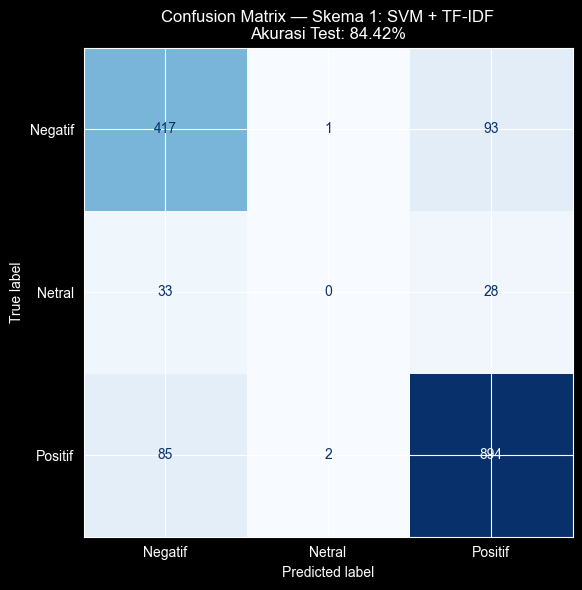

In [6]:
# Cell 6: Confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_names)
disp.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion Matrix — Skema 1: SVM + TF-IDF\nAkurasi Test: {test_acc*100:.2f}%')
plt.tight_layout()
plt.savefig('data/scheme1_confusion_matrix.png', dpi=150)
plt.show()

In [ ]:
# Cell 7: Save models
joblib.dump(tfidf, 'models/tfidf_vectorizer.pkl')
joblib.dump(svm, 'models/svm_model.pkl')
print("Models saved:")
print("  models/tfidf_vectorizer.pkl")
print("  models/svm_model.pkl")